**필수 라이브러리 설치**

In [1]:
# 필수 라이브러리 설치 (가장 안정적인 조합)
!pip install opendartreader finance-datareader transformers scikit-learn
!pip install pykrx

# 1. 나눔 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

!pip install dart-fss
!pip install dart-fss pandas

# 2. 실행 후 반드시 [런타임 다시 시작] 하세요!

INFO: pip is looking at multiple versions of opendartreader to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.0/65.0 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 99.3 MB/s eta 0:00:00
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (119 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/pe

**KoBERT 언어모델 사용**

In [2]:
%%time
# 이 셀을 실행하여 어디서 시간이 걸리는지 체크합니다.

import pandas as pd
import numpy as np
import OpenDartReader
import FinanceDataReader as fdr
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

import torch
from transformers import AutoTokenizer, AutoModel

# KoBERT 모델과 토크나이저 로드 (HuggingFace의 skt/kobert-base-v1 활용)
tokenizer = AutoTokenizer.from_pretrained("skt/kobert-base-v1", last_hidden_state=True)
model = AutoModel.from_pretrained("skt/kobert-base-v1")

# GPU 사용 가능 시 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

import time
import re
import numpy as np
import pandas as pd
from datetime import datetime
from bs4 import BeautifulSoup
from pykrx import stock
from sentence_transformers import SentenceTransformer

import time

print("✅ 기본 라이브러리 로드 완료!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/535 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/371k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/369M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

KRX 로그인 실패: KRX_ID 또는 KRX_PW 환경 변수가 설정되지 않았습니다.
✅ 기본 라이브러리 로드 완료!
CPU times: user 18.5 s, sys: 4.35 s, total: 22.9 s
Wall time: 30.6 s


**DART API연결**

In [4]:
# API 키 설정
API_KEY = 'c7044ad42024e5cb43a8ab7fc9d7b7f6ac9bade0'
dart = OpenDartReader(API_KEY)

# 1초 안에 결과가 나와야 정상입니다.
try:
    sample = dart.list('005930', start='2024-01-01').head(1)
    print("🚀 연결 상태 정상: 최근 공시 제목 -", sample['report_nm'].values[0])
except:
    print("❌ 아직 연결에 문제가 있습니다.")

❌ 아직 연결에 문제가 있습니다.


**KOSPI200 리스트 만들기 (csv파일)**

In [ ]:
import FinanceDataReader as fdr

# 코스피 종목 리스트 가져오기
df_kospi = fdr.StockListing('KOSPI')

# 상위 200개 종목 추출 (보통 시가총액 순으로 정렬되어 나옵니다)
# 만약 정렬이 안 되어 있다면: df_kospi = df_kospi.sort_values('MarCap', ascending=False)
kospi_200 = df_kospi.head(200)

# 엑셀에서 보기 편하게 CSV로 저장
kospi_200[['Name', 'Code']].to_csv('kospi200_list.csv', index=False, encoding='utf-8-sig')

**KOSPI200 10개년 재무정보 추출**

In [ ]:
import OpenDartReader
import pandas as pd
import sqlite3
import time

# 설정
api_key = 'c7044ad42024e5cb43a8ab7fc9d7b7f6ac9bade0'
dart = OpenDartReader(api_key)
csv_filename = 'kospi200_list.csv'
db_name = 'kospi200_10years.db'

# 2. 파일 로드
df_tickers = pd.read_csv(csv_filename)
df_tickers['Code'] = df_tickers['Code'].astype(str).str.zfill(6)

# 3. DB 연결 및 테이블 생성 (총 12개 컬럼)
conn = sqlite3.connect(db_name)
cursor = conn.cursor()
cursor.execute('''
CREATE TABLE IF NOT EXISTS financials_10y (
    code TEXT,
    name TEXT,
    year TEXT,
    revenue REAL,
    op_income REAL,
    net_income REAL,
    assets REAL,
    liabilities REAL,
    equity REAL,
    op_margin REAL,
    roe REAL,
    net_margin REAL,  -- 순이익률 컬럼 추가
    PRIMARY KEY (code, year)
)
''')

def get_integrated_data_10y(code, year):
    try:
        df = dart.finstate_all(code, year)
        if df is None or df.empty: return None

        res = {'rev': 0, 'op': 0, 'ni': 0, 'as': 0, 'li': 0, 'eq': 0}
        mapping = {
            'rev': ['매출액', '영업수익', '수익(매출액)', '이자수익', '보험료수익', '운용수익', '매출', '수익'],
            'op': ['영업이익', '영업이익(손실)', '보험영업이익', '이자이익', '영업손익', '분기영업이익'],
            'ni': ['당기순이익', '당기순이익(손실)', '연결당기순이익', '당기순이익 (손실)', '분기순이익', '총포괄이익'],
            'as': ['자산총계', '자산 총계', '자산', '자산합계'],
            'li': ['부채총계', '부채 총계', '부채', '부채합계'],
            'eq': ['자본총계', '자본 총계', '자본', '자본합계', '지배기업소유주지분']
        }

        for _, row in df.iterrows():
            raw_nm = str(row['account_nm']).replace(" ", "").replace("\n", "")
            try:
                val = float(row['thstrm_amount']) if pd.notnull(row['thstrm_amount']) else 0
            except: continue

            for key, names in mapping.items():
                if raw_nm in names and res[key] == 0:
                    res[key] = val

        f = {k: round(v / 100000000, 2) for k, v in res.items()}

        # 지표 계산 (분모 0 처리 필수)
        op_margin = round((f['op'] / f['rev'] * 100), 2) if f['rev'] != 0 else 0
        roe = round((f['ni'] / f['eq'] * 100), 2) if f['eq'] != 0 else 0
        net_margin = round((f['ni'] / f['rev'] * 100), 2) if f['rev'] != 0 else 0

        # 총 9개 데이터 반환
        return [f['rev'], f['op'], f['ni'], f['as'], f['li'], f['eq'], op_margin, roe, net_margin]
    except:
        return None

# 4. 수집 루프 (2014-2023)
years = [str(y) for y in range(2014, 2024)]
print(f"🚀 200개 기업 10개년 데이터 수집 시작...")

for idx, row in df_tickers.iterrows():
    code, name = row['Code'], row['Name']

    for year in years:
        cursor.execute("SELECT 1 FROM financials_10y WHERE code=? AND year=?", (code, year))
        if cursor.fetchone(): continue

        print(f"[*] {name}({code}) {year}년 분석 중... ({idx+1}/200)", end="\r")

        data = get_integrated_data_10y(code, year)
        if data:
            # INSERT VALUES에 들어가는 리스트의 개수는 총 12개 (code, name, year + data 9개)
            cursor.execute('INSERT OR REPLACE INTO financials_10y VALUES (?,?,?,?,?,?,?,?,?,?,?,?)', [code, name, year] + data)
            conn.commit()

        time.sleep(0.15)

conn.close()
print("\n✅ 모든 작업 완료!")

🚀 200개 기업 10개년 데이터 수집 시작...
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
{'status': '013', 'message': '조회된 데이타가 없습니다.'}
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
{'status': '013', 'message': '조회된 데이타가 없습니다.'}
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='

In [ ]:
def export_10y_to_excel(db_file='kospi200_10years.db'):
    conn = sqlite3.connect(db_file)
    df = pd.read_sql("SELECT * FROM financials_10y", conn)

    # 분석용 피벗 테이블 생성 (가로: 연도, 세로: 기업명)
    revenue_trend = df.pivot(index='name', columns='year', values='revenue')
    op_income_trend = df.pivot(index='name', columns='year', values='op_income')

    with pd.ExcelWriter('KOSPI200_10개년_재무추이.xlsx') as writer:
        df.to_excel(writer, sheet_name='Raw_Data', index=False)
        revenue_trend.to_excel(writer, sheet_name='매출액_추이')
        op_income_trend.to_excel(writer, sheet_name='영업이익_추이')

    conn.close()
    print("📂 엑셀 파일 저장 완료: KOSPI200_10개년_재무추이.xlsx")

export_10y_to_excel()

📂 엑셀 파일 저장 완료: KOSPI200_10개년_재무추이.xlsx


**🚀 Phase 2: 매크로 유전자 기반 테마 분류 엔진 (2014-2023)이 단계에서는 단순히 업종별(IT, 금융 등)로 기업을 나누는 것이 아니라, 거시경제 지표(금리, 환율, 유가, 금)에 반응하는 기업별 '매크로 유전자'를 추출하여 8개의 동적 테마로 분류합니다.**


1. 분석 목적매크로 민감도 수치화: 각 기업의 주가가 거시경제 변수에 얼마나 민감하게 반응하는지 상관계수로 산출합니다.동적 테마 구축: 고정된 섹터가 아닌, 매년 변화하는 경제 환경 속에서 실제로 같이 움직이는 기업군을 포착합니다.3차 예측 가중치 생성: 향후 AI 주가 예측 모델이 참고할 지표별 중요도(Feature Weight)를 DB화합니다
우리가 사용하는 코드(price.corr(macro_df))는 내부적으로 피어슨 상관계수 공식을 사용합니다.$$r = \frac{\sum (X - \bar{X})(Y - \bar{Y})}{\sqrt{\sum (X - \bar{X})^2 \sum (Y - \bar{Y})^2}}$$

2.   핵심 알고리즘 및 프로세스데이터 정밀화 (Weekly Data): 월간 데이터의 노이즈를 줄이기 위해 주간 수익률 단위로 분석하여 1년당 약 52개의 데이터 포인트를 확보합니다.유전자 추출 (Sensitivity Analysis): 4대 매크로 지표($Interest, FX, Oil, Gold$)와 개별 종목 주가 간의 상관계수를 계산하여 기업별 '민감도 벡터'를 생성합니다.군집화 (K-Means Clustering): 생성된 민감도 벡터를 바탕으로 거시경제 반응 체계가 가장 유사한 기업들을 8개 테마로 묶습니다.표준 가중치 확정 (Intelligence): 각 테마에 속한 기업들의 평균 수치를 계산하여, 해당 테마의 '대표 매크로 유전자'를 확정합니다
3.   **생성되는 결과물 (3차 파이프라인 입력값)company_yearly_sensitivities.csv: 기업별 연도별 매크로 반응도 (Raw Data)theme_yearly_weights.csv: 테마별 표준 가중치 (AI 모델의 직접적 가중치로 활용)company_theme_mapping.csv: 기업별 연도별 테마 소속 기록**


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import FinanceDataReader as fdr
from tqdm import tqdm
import warnings

warnings.filterwarnings('ignore')

# 1. 초기 설정
df_tickers = pd.read_csv('kospi200_list.csv')
df_tickers['Code'] = df_tickers['Code'].astype(str).str.zfill(6)
start_year, end_year = 2014, 2023
macro_factors = ['Interest', 'FX', 'Oil', 'Gold']
n_clusters = 8

# 2. 매크로 전체 데이터 수집 (FRED)
print("🌐 매크로 시계열 데이터 수집 중...")
macro_dict = {'Interest': 'REAINTRATREARAT10Y', 'FX': 'DEXKOUS', 'Oil': 'POILWTIUSDM', 'Gold': 'ID7108'}
macro_data = {f: fdr.DataReader(f'FRED:{s}', f'{start_year}-01-01', f'{end_year}-12-31') for f, s in macro_dict.items()}
macro_df = pd.concat(macro_data, axis=1).ffill().bfill().resample('W').last().pct_change().dropna()
macro_df.columns = macro_factors

# 결과 저장용 바구니
company_sens_data = []  # 파일 1용
theme_weight_data = []  # 파일 2용
mapping_df = pd.DataFrame(index=df_tickers['Name']) # 파일 3용

# 3. 연도별 루프 (2014 ~ 2023)
print(f"🚀 {start_year}년~{end_year}년 10개년 통합 분석 및 테마 추출 시작...")

for year in range(start_year, end_year + 1):
    y_start, y_end = f"{year}-01-01", f"{year}-12-31"
    m_year = macro_df.loc[y_start:y_end]

    current_year_features = []
    current_year_corps = []

    # 각 연도 내 기업별 분석 (진행바 표시)
    for _, row in tqdm(df_tickers.iterrows(), total=len(df_tickers), desc=f"Analyzing {year}"):
        try:
            price = fdr.DataReader(row['Code'], y_start, y_end)['Close'].resample('W').last().pct_change().dropna()
            common_idx = price.index.intersection(m_year.index)
            if len(common_idx) < 25: continue # 주간 데이터 25개 이상 확보 시에만

            # 상관계수(유전자) 산출
            vector = [price.loc[common_idx].corr(m_year.loc[common_idx, f]) for f in macro_factors]
            if any(np.isnan(v) for v in vector): continue

            # 데이터 축적
            current_year_features.append(vector)
            current_year_corps.append(row['Name'])
            company_sens_data.append([year, row['Name']] + vector)
        except: continue

    # 테마 분류 및 테마별 가중치 산출
    if len(current_year_features) >= n_clusters:
        scaled_x = StandardScaler().fit_transform(current_year_features)
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        labels = kmeans.fit_predict(scaled_x)

        # 기업-테마 매핑 저장
        mapping_df = mapping_df.join(pd.Series(labels, index=current_year_corps, name=f'Theme_{year}'), how='left')

        # 테마별 평균 가중치(DNA) 저장
        temp_df = pd.DataFrame(current_year_features, columns=macro_factors)
        temp_df['Theme'] = labels
        theme_avg = temp_df.groupby('Theme').mean()
        for t_id, row_avg in theme_avg.iterrows():
            theme_weight_data.append([year, t_id] + row_avg.tolist())

# 4. 최종 파일 저장
print("\n💾 분석 완료! 결과 파일 생성 중...")
pd.DataFrame(company_sens_data, columns=['Year', 'Name']+macro_factors).to_csv("company_yearly_sensitivities.csv", index=False, encoding='utf-8-sig')
pd.DataFrame(theme_weight_data, columns=['Year', 'Theme']+macro_factors).to_csv("theme_yearly_weights.csv", index=False, encoding='utf-8-sig')
mapping_df.fillna('N/A').to_csv("company_theme_mapping.csv", encoding='utf-8-sig')

print("✅ 모든 파일이 성공적으로 저장되었습니다.")

🌐 매크로 시계열 데이터 수집 중...
🚀 2014년~2023년 10개년 통합 분석 및 테마 추출 시작...


Analyzing 2023: 100%|██████████| 200/200 [03:01<00:00,  1.10it/s]


💾 분석 완료! 결과 파일 생성 중...
✅ 모든 파일이 성공적으로 저장되었습니다.


**연도별 테마분류결과**
N/A는 일정기간 거래정지 혹은 그 년도에 아직 상장이 안된 상태라 테마분류에 포함되지 않음.

In [ ]:
import pandas as pd

# 1. 데이터 로드
weights = pd.read_csv('theme_yearly_weights.csv')
mapping = pd.read_csv('company_theme_mapping.csv')

def generate_full_report():
    report_lines = []
    years = sorted(weights['Year'].unique())

    # 실제 컬럼명 자동 감지
    all_cols = weights.columns.tolist()
    macro_cols = [c for c in all_cols if c in ['Interest', 'FX', 'Oil', 'Gold',
                                              'Interest_W', 'FX_W', 'Oil_W', 'Gold_W']]

    for year in years:
        header = f"\n📅 [{year}년 매크로 테마 분석 결과]"
        print(header)
        report_lines.append(header)
        print("="*100)
        report_lines.append("="*100)

        year_weights = weights[weights['Year'] == year]
        col_name = f'Theme_{year}'

        if col_name not in mapping.columns:
            continue

        for _, row in year_weights.iterrows():
            t_id = int(float(row['Theme']))

            # 해당 테마 소속 종목 추출 (N/A 제외 및 타입 일치)
            members = mapping[mapping[col_name].apply(lambda x: str(x).split('.')[0] == str(t_id))]['Name'].tolist()

            # 매크로 민감도 수치 요약
            sens = row[macro_cols]
            main_factor = sens.abs().astype(float).idxmax()
            main_val = float(sens[main_factor])

            summary = f"테마 #{t_id:^2} | 주요동인: {main_factor:^10} ({main_val:+.3f}) | 종목수: {len(members):>3}개"
            member_list = f"   ㄴ 종목: {', '.join(members)}"

            print(summary)
            print(member_list[:150] + "..." if len(member_list) > 150 else member_list) # 너무 길면 생략해서 출력
            print("-" * 100)

            report_lines.append(summary)
            report_lines.append(member_list)
            report_lines.append("-" * 100)

    # 전체 리스트를 텍스트 파일로 저장
    with open("full_macro_report_2014_2023.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(report_lines))
    print(f"\n✅ 10개년 전체 리스트가 'full_macro_report_2014_2023.txt'로 저장되었습니다.")

# 실행
generate_full_report()


📅 [2014년 매크로 테마 분석 결과]
테마 #0  | 주요동인:    Gold    (+0.284) | 종목수:  11개
   ㄴ 종목: 두산에너빌리티, POSCO홀딩스, HD한국조선해양, 두산, 현대건설, 삼양식품, LG디스플레이, 한온시스템, GS건설, 이마트, 제일기획
----------------------------------------------------------------------------------------------------
테마 #1  | 주요동인:     FX     (+0.161) | 종목수:  21개
   ㄴ 종목: 삼성전기, 삼성생명, 기아, 한화에어로스페이스, LS ELECTRIC, 한국전력, SK텔레콤, 기업은행, KT, 한화솔루션, 금호석유화학, 롯데케미칼, 효성, 한국가스공사, 현대엘리베이터, 현대해상, HD현대마린엔진, 코리안리, 한전KPS, 농심, 코스...
----------------------------------------------------------------------------------------------------
테마 #2  | 주요동인:     FX     (-0.199) | 종목수:  29개
   ㄴ 종목: SK, 셀트리온, LG전자, 미래에셋증권, NAVER, LG이노텍, HMM, 현대글로비스, 한국금융지주, NH투자증권, 삼성증권, DB하이텍, 아모레퍼시픽, 코웨이, 엘앤에프, SKC, CJ, KCC, 롯데쇼핑, 한올바이오파마, CJ제일제당, 코리아써키...
----------------------------------------------------------------------------------------------------
테마 #3  | 주요동인:    Gold    (+0.102) | 종목수:  28개
   ㄴ 종목: SK하이닉스, 현대차, 현대모비스, 삼성SDI, 한화오션, 삼성중공업, 삼성화재, LG화학, LG, 한국항공우주, 대우건설, 한화, 키움증권, 한진

**테마별 상관계수** 2023년도만 보기!

In [ ]:
# 1. 테마별 평균 상관계수 (DNA) 추출
theme_dna = result_df.groupby('Theme').mean()

print(f"📊 2023년 테마별 매크로 유전자(상관계수) 성적표")
print("="*85)
print(f"{'테마번호':^8} | {'금리(Int)':^10} | {'환율(FX)':^10} | {'유가(Oil)':^10} | {'금(Gold)':^10}")
print("-" * 85)

for i in range(len(theme_dna)):
    row = theme_dna.iloc[i]
    print(f"Theme #{i:^5} | {row['Interest']:>10.4f} | {row['FX']:>10.4f} | {row['Oil']:>10.4f} | {row['Gold']:>10.4f}")

print("="*85)
print("💡 수치 해석 가이드:")
print("  - (+): 해당 지표가 오를 때 주가도 같이 오르는 경향 (정상관)")
print("  - (-): 해당 지표가 오를 때 주가는 떨어지는 경향 (역상관)")
print("  - 0에 가까울수록: 해당 매크로 지표의 변화에 무덤덤한 반응")

📊 2023년 테마별 매크로 유전자(상관계수) 성적표
  테마번호   |  금리(Int)   |   환율(FX)   |  유가(Oil)   |  금(Gold)  
-------------------------------------------------------------------------------------
Theme #  0   |    -0.0745 |    -0.0625 |    -0.0127 |     0.0871
Theme #  1   |    -0.0675 |    -0.2290 |     0.1705 |     0.1633
Theme #  2   |     0.1162 |    -0.1569 |     0.1844 |    -0.0767
Theme #  3   |    -0.0158 |    -0.3131 |    -0.0037 |     0.0833
Theme #  4   |     0.0421 |     0.0750 |     0.1193 |     0.0560
Theme #  5   |    -0.2226 |    -0.2252 |     0.0390 |     0.3285
Theme #  6   |    -0.1121 |    -0.3542 |    -0.0975 |     0.1892
Theme #  7   |     0.1917 |    -0.1674 |    -0.1492 |    -0.1637
💡 수치 해석 가이드:
  - (+): 해당 지표가 오를 때 주가도 같이 오르는 경향 (정상관)
  - (-): 해당 지표가 오를 때 주가는 떨어지는 경향 (역상관)
  - 0에 가까울수록: 해당 매크로 지표의 변화에 무덤덤한 반응


**테마별 거시지표 예민성** 시각화 자료 2023년도만

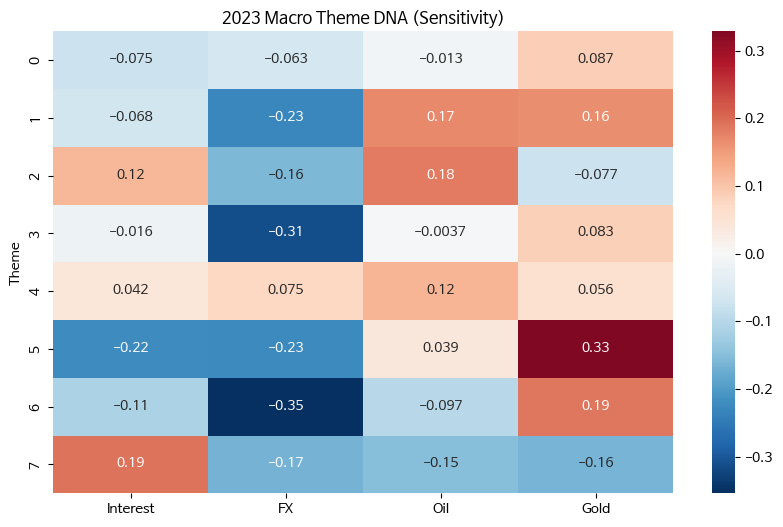

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(theme_dna, annot=True, cmap='RdBu_r', center=0)
plt.title(f"2023 Macro Theme DNA (Sensitivity)")
plt.show()

**KOSPI200 2014-2023년도 종가데이터 수집**

In [ ]:
import FinanceDataReader as fdr
import sqlite3
import pandas as pd
from tqdm.auto import tqdm
import time
import os

def build_db_from_csv(csv_path='kospi200_list.csv', db_name='kospi200_close_2014_2023.db'):
    # 1. CSV 파일에서 종목 리스트 불러오기
    if not os.path.exists(csv_path):
        print(f"❌ 에러: {csv_path} 파일을 찾을 수 없습니다.")
        return

    df_list = pd.read_csv(csv_path)

    # CSV의 컬럼명이 'code', 'Code', '종목코드' 등 다를 수 있으니 확인 후 수정하세요.
    # 보통 소문자 'code'로 가정합니다.
    if 'code' in df_list.columns:
        target_codes = df_list['code'].astype(str).str.zfill(6).unique().tolist()
    elif 'Code' in df_list.columns:
        target_codes = df_list['Code'].astype(str).str.zfill(6).unique().tolist()
    else:
        print("❌ 에러: CSV 파일에 'code' 또는 'Code' 컬럼이 없습니다.")
        return

    conn = sqlite3.connect(db_name)
    cursor = conn.cursor()

    # 기존 데이터 삭제 후 새로 생성 (깔끔한 구축을 위해)
    cursor.execute("DROP TABLE IF EXISTS stock_prices")
    cursor.execute('''
        CREATE TABLE stock_prices (
            Date TEXT,
            Code TEXT,
            Close REAL
        )
    ''')

    print(f"🚀 CSV 리스트 내 {len(target_codes)}개 종목 수집 시작 (2014-2023)")

    # 진행률 표시 바
    pbar = tqdm(target_codes, desc="종가 데이터 수집 중", unit="종목")

    for code in pbar:
        pbar.set_postfix(current=code)

        try:
            # 주가 데이터 호출
            df = fdr.DataReader(code, '2014-01-01', '2023-12-31')

            if not df.empty:
                df = df[['Close']].reset_index()
                df['Code'] = code
                df['Date'] = df['Date'].dt.strftime('%Y-%m-%d')

                # DB 저장
                df[['Date', 'Code', 'Close']].to_sql('stock_prices', conn, if_exists='append', index=False)

            # API 서버 부하 방지
            time.sleep(0.1)

        except Exception as e:
            tqdm.write(f"⚠️ {code} 수집 중 에러 발생: {e}")
            continue

    # ⚡ 조회 성능 극대화를 위한 인덱스 생성
    print("\n⚡ 최적화 인덱스 생성 중...")
    cursor.execute("CREATE INDEX idx_code_date ON stock_prices (Code, Date)")

    conn.commit()
    conn.close()
    print(f"✅ DB 구축 완료: {db_name}")

# --- 실행 ---
build_db_from_csv('kospi200_list.csv')

🚀 CSV 리스트 내 200개 종목 수집 시작 (2014-2023)


종가 데이터 수집 중:   0%|          | 0/200 [00:00<?, ?종목/s]


⚡ 최적화 인덱스 생성 중...
✅ DB 구축 완료: kospi200_close_2014_2023.db


**학습용 데이터셋 통합하기**
########## 여기서부터 파일넣고 하시면 됩니다#########

In [7]:
import pandas as pd
import sqlite3
import re

# 1. CSV 데이터 로드
list_df = pd.read_csv('kospi200_list.csv')
theme_map_df = pd.read_csv('company_theme_mapping.csv')
theme_weights_df = pd.read_csv('theme_yearly_weights.csv')
sensitivities_df = pd.read_csv('company_yearly_sensitivities.csv')

# 2. DB 데이터 로드
conn_fin = sqlite3.connect('kospi200_10years.db')
financials_df = pd.read_sql_query("SELECT * FROM financials_10y", conn_fin)
conn_fin.close()

conn_price = sqlite3.connect('kospi200_close_2014_2023.db')
prices_df = pd.read_sql_query("SELECT * FROM stock_prices", conn_price)
conn_price.close()

# --- 데이터 전처리 시작 ---

# [Step 1] 테마 매핑 데이터 변환 (Melt) - r'(\d+)' 로 수정하여 SyntaxWarning 해결
theme_long = theme_map_df.melt(id_vars=['Name'], var_name='Year', value_name='Theme')
theme_long['Year'] = theme_long['Year'].str.extract(r'(\d+)').astype(int)
theme_long = theme_long.dropna(subset=['Theme'])
theme_long['Theme'] = theme_long['Theme'].astype(int)

# [Step 2] 주가 데이터 전처리
prices_df['Date'] = pd.to_datetime(prices_df['Date'])
prices_df['Year'] = prices_df['Date'].dt.year.astype(int) # int 타입 확정
prices_df['Code'] = prices_df['Code'].astype(str).str.zfill(6) # 6자리 문자열 확정

# 종목명 결합
list_df['Code'] = list_df['Code'].astype(str).str.zfill(6)
prices_df = pd.merge(prices_df, list_df, on='Code', how='left')

# [Step 3] 개별 기업 민감도 결합 전 타입 통일
sensitivities_df['Year'] = sensitivities_df['Year'].astype(int)
merged_df = pd.merge(prices_df, sensitivities_df, on=['Year', 'Name'], how='left')

# [Step 4] 테마 정보 결합 전 타입 통일
theme_weights_df['Year'] = theme_weights_df['Year'].astype(int)
theme_weights_df['Theme'] = theme_weights_df['Theme'].astype(int)

merged_df = pd.merge(merged_df, theme_long, on=['Year', 'Name'], how='left')
merged_df = pd.merge(merged_df, theme_weights_df, on=['Year', 'Theme'], how='left', suffixes=('_stock', '_theme'))

# [Step 5] 재무 DNA 결합 전 타입 통일 (가장 중요한 부분)
financials_df.rename(columns={'code': 'Code', 'year': 'Year'}, inplace=True)
financials_df['Year'] = financials_df['Year'].astype(int) # 에러 해결의 핵심: int로 변환
financials_df['Code'] = financials_df['Code'].astype(str).str.zfill(6)

# name 컬럼 중복 방지를 위해 drop 후 병합
merged_df = pd.merge(merged_df, financials_df.drop(columns=['name'], errors='ignore'), on=['Year', 'Code'], how='left')

# --- 최종 데이터 정리 ---
final_dataset = merged_df.sort_values(['Code', 'Date']).reset_index(drop=True)

print("✅ 모든 에러가 해결되고 데이터셋 통합이 완료되었습니다!")
print(f"최종 데이터 크기: {final_dataset.shape}")

✅ 모든 에러가 해결되고 데이터셋 통합이 완료되었습니다!
최종 데이터 크기: (408782, 23)


**XGBoost (Extreme Gradient Boosting)**


Training Strategy: Sliding Window
과거의 데이터가 현재의 시장 질서를 대변하지 못하는 주식 시장의 특성을 반영하여 '슬라이딩 윈도우' 방식을 채택했습니다.

Window Structure: 3-Year Training → 1-Year Prediction

Learning Process: 1.  2014-2016년 데이터를 학습하여 2017년을 예측 및 검증합니다.
2.  윈도우를 1년 뒤로 밀어 2015-2017년 데이터를 학습하고 2018년을 예측합니다.
3.  이 과정을 반복하여 모델이 최신 시장 트렌드(예: 고금리 국면, 팬데믹 등)를 지속적으로 업데이트하도록 설계되었습니다.

--- [재무 변화량(Diff) 추가 버전 학습 시작] ---
연도         | RMSE       | 가장 중요한 변수      
-------------------------------------------------------
2017년 예측 | 0.2313 | FX_stock
2018년 예측 | 0.1843 | Gold_theme
2019년 예측 | 0.1879 | Gold_theme
2020년 예측 | 0.3267 | debt_ratio
2021년 예측 | 0.2350 | Interest_theme
2022년 예측 | 0.1744 | Interest_theme
2023년 예측 | 0.2506 | Interest_theme


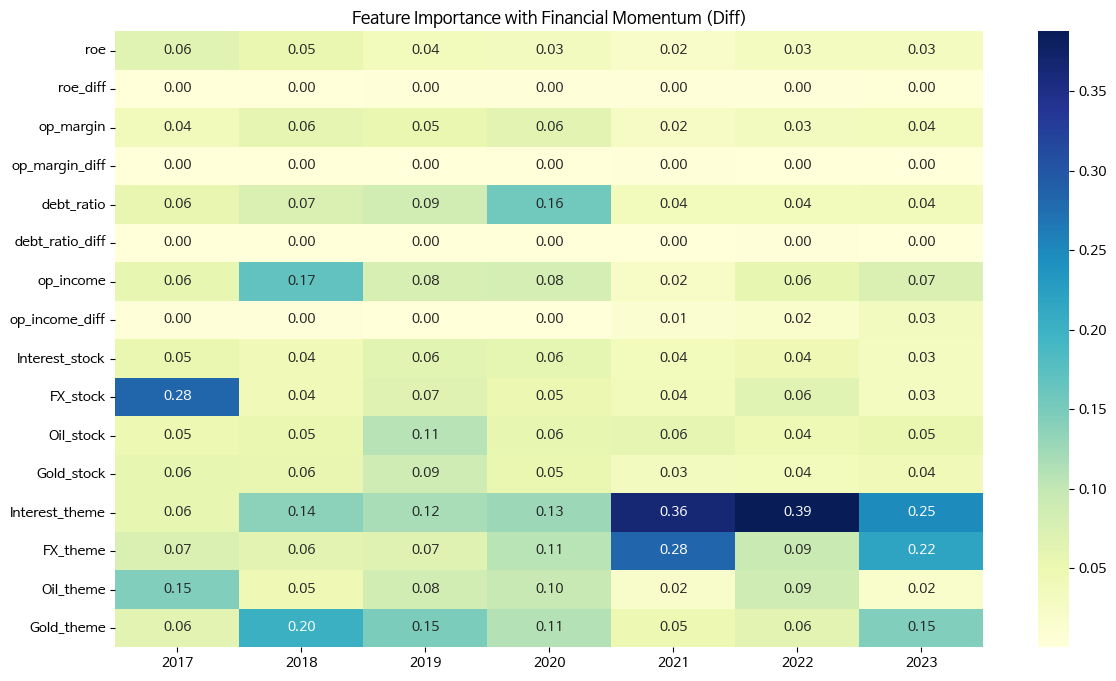

In [12]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. 재무 변화량(Diff) 피처 생성
# 기업별(Code), 연도별로 정렬하여 전년도와의 차이를 계산합니다.
fin_cols = ['roe', 'op_margin', 'debt_ratio', 'op_income']
for col in fin_cols:
    final_dataset[f'{col}_diff'] = final_dataset.groupby('Code')[col].diff()

# 2. Target 생성 (3개월/60일 뒤 수익률)
target_days = 60
final_dataset['Target_Return'] = final_dataset.groupby('Code')['Close'].shift(-target_days) / final_dataset['Close'] - 1

# 3. 확장된 피처 리스트 정의
# 기존 지표 + 변화량(diff) 지표를 모두 포함합니다.
features = [
    'roe', 'roe_diff',
    'op_margin', 'op_margin_diff',
    'debt_ratio', 'debt_ratio_diff',
    'op_income', 'op_income_diff',
    'Interest_stock', 'FX_stock', 'Oil_stock', 'Gold_stock',
    'Interest_theme', 'FX_theme', 'Oil_theme', 'Gold_theme'
]
target = 'Target_Return'

# 결측치 처리 (Diff 피처 생성 시 첫 해는 NaN이 되므로 학습에서 제외됨)
train_df = final_dataset.dropna(subset=[target, 'roe_diff', 'Interest_stock']).copy()

# 4. 결과 기록용
importance_history = []
window_years = []

print(f"--- [재무 변화량(Diff) 추가 버전 학습 시작] ---")
print(f"{'연도':<10} | {'RMSE':<10} | {'가장 중요한 변수':<15}")
print("-" * 55)

# 5. 슬라이딩 윈도우 루프
window_size = 3
for start_year in range(2014, 2021):
    train_years = list(range(start_year, start_year + window_size))
    test_year = start_year + window_size

    X_train = train_df[train_df['Year'].isin(train_years)][features]
    y_train = train_df[train_df['Year'].isin(train_years)][target]
    X_test = train_df[train_df['Year'] == test_year][features]
    y_test = train_df[train_df['Year'] == test_year][target]

    if len(X_test) == 0: continue

    model = xgb.XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=6,
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_train, y_train)

    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    importances = model.feature_importances_
    top_feature = features[np.argmax(importances)]
    importance_history.append(importances)
    window_years.append(test_year)

    print(f"{test_year}년 예측 | {rmse:.4f} | {top_feature}")

# 6. 시각화
if importance_history:
    plt.figure(figsize=(14, 8))
    importance_df = pd.DataFrame(importance_history, columns=features, index=window_years)
    # 중요도 상위 10개 피처만 강조해서 보기 위해 정렬 및 시각화
    sns.heatmap(importance_df.T, annot=True, cmap='YlGnBu', fmt='.2f')
    plt.title("Feature Importance with Financial Momentum (Diff)")
    plt.show()

In [18]:
# @title 📈 종목별 3개월 뒤 수익률 예측 시뮬레이터 (오류 수정 버전)

import pandas as pd
import numpy as np
import xgboost as xgb

# 1. 사용자로부터 입력 받기
input_name = input("🔍 예측하고 싶은 종목명을 입력하세요 (예: 삼성전자, 셀트리온): ").strip()
input_year = int(input("📅 분석 기준 연도를 입력하세요 (2017~2023): "))

# 2. 해당 조건의 데이터 추출
target_data = train_df[(train_df['Name'] == input_name) & (train_df['Year'] == input_year)].sort_values('Date')

if not target_data.empty:
    # 해당 연도의 첫 번째 데이터(공시 시점 가정) 선택
    sample = target_data.head(1)

    # 3. 모델 추론 (Inference)
    # final_model 또는 model 객체를 사용하여 예측
    pred_return = final_model.predict(sample[features])[0]
    actual_return = sample[target].values[0]

    current_price = sample['Close'].values[0]
    predicted_price = current_price * (1 + pred_return)
    actual_price = current_price * (1 + actual_return)

    # 4. 결과 대시보드 출력
    print("\n" + "="*60)
    print(f"🚀 [{input_name}] {input_year}년 공시 시점 분석 결과")
    print("="*60)
    print(f"💰 분석 당시 주가    : {current_price:,.0f}원")
    print(f"📊 모델 예측 수익률  : {pred_return*100:+.2f}%")  # 오타 수정 완료!
    print(f"🎯 모델 예측 목표가  : {predicted_price:,.0f}원")
    print("-" * 60)
    print(f"✅ 실제 3개월 뒤 수익률: {actual_return*100:+.2f}%")
    print(f"📉 실제 3개월 뒤 주가  : {actual_price:,.0f}원")
    print(f"📌 예측 오차(Error)  : {abs(pred_return - actual_return)*100:.2f}%p")
    print("="*60)

    # 5. 판단 근거 요약
    print(f"\n💡 AI가 판단에 활용한 주요 지표 ({input_name} 상태):")
    print(f"  • 재무 모멘텀 (ROE 변화) : {sample['roe_diff'].values[0]:+.2f}")
    print(f"  • 금리 테마 민감도      : {sample['Interest_theme'].values[0]:.4f}")
    print(f"  • 환율 종목 민감도      : {sample['FX_stock'].values[0]:.4f}")
    print(f"  • 영업이익 변화량       : {sample['op_income_diff'].values[0]:+,.0f} (백만원)")

else:
    print(f"❌ 데이터를 찾을 수 없습니다. 종목명('{input_name}')과 연도({input_year})를 다시 확인해주세요.")

🔍 예측하고 싶은 종목명을 입력하세요 (예: 삼성전자, 셀트리온): SK하이닉스
📅 분석 기준 연도를 입력하세요 (2017~2023): 2022

🚀 [SK하이닉스] 2022년 공시 시점 분석 결과
💰 분석 당시 주가    : 128,500원
📊 모델 예측 수익률  : -5.25%
🎯 모델 예측 목표가  : 121,759원
------------------------------------------------------------
✅ 실제 3개월 뒤 수익률: -8.95%
📉 실제 3개월 뒤 주가  : 117,000원
📌 예측 오차(Error)  : 3.70%p

💡 AI가 판단에 활용한 주요 지표 (SK하이닉스 상태):
  • 재무 모멘텀 (ROE 변화) : -11.92
  • 금리 테마 민감도      : 0.0418
  • 환율 종목 민감도      : -0.2122
  • 영업이익 변화량       : -56,009 (백만원)
